# Preprocessing and clustering 3k PBMCs (legacy workflow)

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import pooch

数据包含来自健康捐献者的 3000 个外周血单核细胞 (PBMC)

In [2]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scanpy_learn"),
    base_url="https://cf.10xgenomics.com/samples/cell/pbmc3k/",
    # 手动登记文件；None表示暂不指定校验哈希
    registry={
        "pbmc3k_filtered_gene_bc_matrices.tar.gz": None,
    },
)

In [3]:
from pathlib import Path

file = EXAMPLE_DATA.fetch(
    "pbmc3k_filtered_gene_bc_matrices.tar.gz",
    # fetch表示从pooch对象中的链接中根据文件名下载文件，再返回文件路径
)

# next()找到第一个目录就停止
data_path = next(
    (Path(filename).parent for filename in Path(file).parent.joinpath("pbmc3k_data").rglob("matrix.mtx")),
    # 在压缩包路径下新建pbmc3k_data
    None # 找到返回路径的path类型否则返回None
)
# 在可能已经存在的解压文件夹中找名字为matrix.mtx的filename，返回该文件的parent路径
# 其实相当于这三个文件的路径
# Path()将字符型路径转化为path对象，便于使用parent找到目录，name返回文件名，以及后续使用\进行拼接
# rglob()是Path对象用来递归查找文件或文件夹的方法

# 若无目标文件再进行解压
if data_path is None:
    untar = pooch.Untar(extract_dir="pbmc3k_data")  # 创建一个解压工具，解压到pbmc3k_data文件夹下
    files = untar(file, "download", EXAMPLE_DATA)  # 调用untar解压
    # “download”按刚下载完成的情况处理，从而执行解压不会重新下载
    data_path = next(
        Path(filename).parent
        for filename in files
        if Path(filename).name == "matrix.mtx"
    )

print("数据目录：", data_path)

数据目录： C:\Users\Yeliang\AppData\Local\scanpy_learn\scanpy_learn\Cache\pbmc3k_data\filtered_gene_bc_matrices\hg19


In [4]:
adata = sc.read_10x_mtx(
    str(data_path),             # 三个数据文件所在的文件夹
    var_names="gene_symbols",   # 使用基因符号作为var表索引（还可选gene_ids）
    cache=False,
)
adata.var_names_make_unique()
adata


AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

说明var表有一列gene_ids为注释，obs表目前只有索引没有数据

In [5]:
sc.settings.verbosity = 3 # verbosity控制Scanpy在运行时显示多少信息
# 从0～3:错误、警告、运行信息、提示信息
sc.set_figure_params(dpi=80, facecolor="white")

# 创建一个Path对象
write_dir = Path.home() / "scanpy_learning" / "pbmc3k" / "write"
# Path.home()这里为C:\Users\Yeliang
write_dir.mkdir(parents=True, exist_ok=True) # 以此路径创建一个文件夹保存输出
# parents=True上级目录不存在就一并创建
# exist_ok=True如果目录已经存在，不报错，也不清空里面的文件
results_file = str(write_dir / "pbmc3k.h5ad") # 此时该文件还未创建

print("分析结果将保存到：", results_file)

分析结果将保存到： C:\Users\Yeliang\scanpy_learning\pbmc3k\write\pbmc3k.h5ad


# Preprocessing

normalizing counts per cell
    finished (0:00:00)


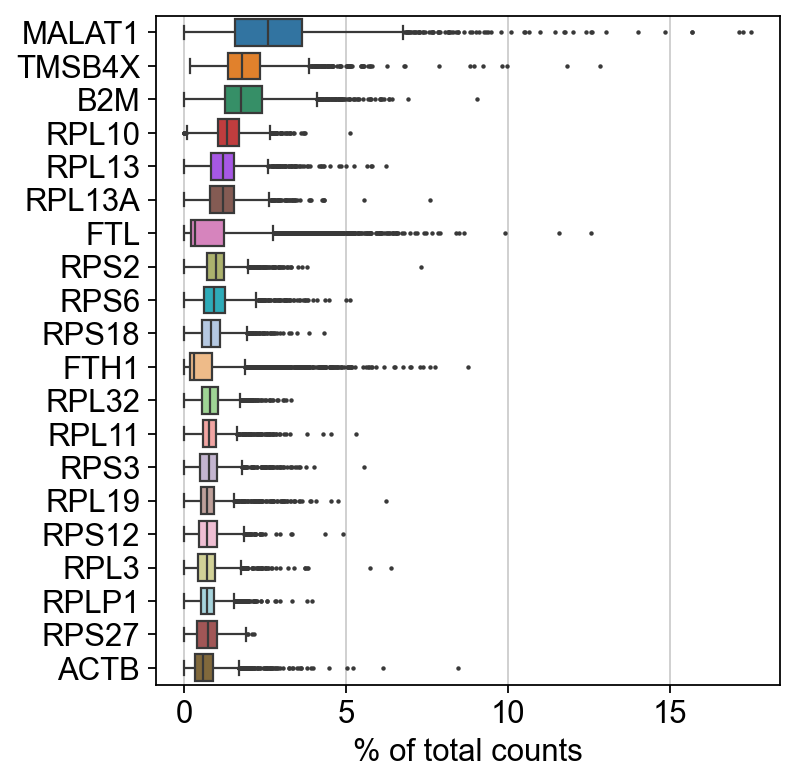

In [6]:
sc.pl.highest_expr_genes(adata, n_top=20) # 画出前20高表达基因

假设n个细胞，对每个基因计算在第i个细胞中的count/第i个细胞细胞中所有基因的count，得到n个值画箱线图
得到k个基因的k个箱线图，按大致高低排序

In [7]:
adata_raw = adata.copy()

In [8]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata

filtered out 19024 genes that are detected in less than 3 cells


AnnData object with n_obs × n_vars = 2700 × 13714
    obs: 'n_genes'
    var: 'gene_ids', 'n_cells'

In [9]:
# 看一下X矩阵100*100的范围内大概什么样
expression_df = pd.DataFrame(
    adata.X[:100, :100].toarray(),
    index=adata.obs_names[:100],
    columns=adata.var_names[:100],
)

expression_df

,AL627309.1,AP006222.2,RP11-206L10.2,RP11-206L10.9,LINC00115,NOC2L,KLHL17,PLEKHN1,RP11-54O7.17,HES4,...,VAMP3,PER3,UTS2,TNFRSF9,PARK7,SLC45A1,RERE,RP5-1115A15.1,ENO1,ENO1-AS1
AAACATACAACCAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACATTGAGCTAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
AAACATTGATCAGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0
AAACCGTGCTTCCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
AAACCGTGTATGCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AAGAGATGGGTAGG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAGATGGAAAACAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
AAGATGGAGAACTC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
AAGATGGAGATAAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0


In [10]:
# Calculate QC，这里只选了线粒体基因
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

In [11]:
obs_df = adata.obs
vars_df = adata.var
# 在jupyter变量中可查看矩阵变化

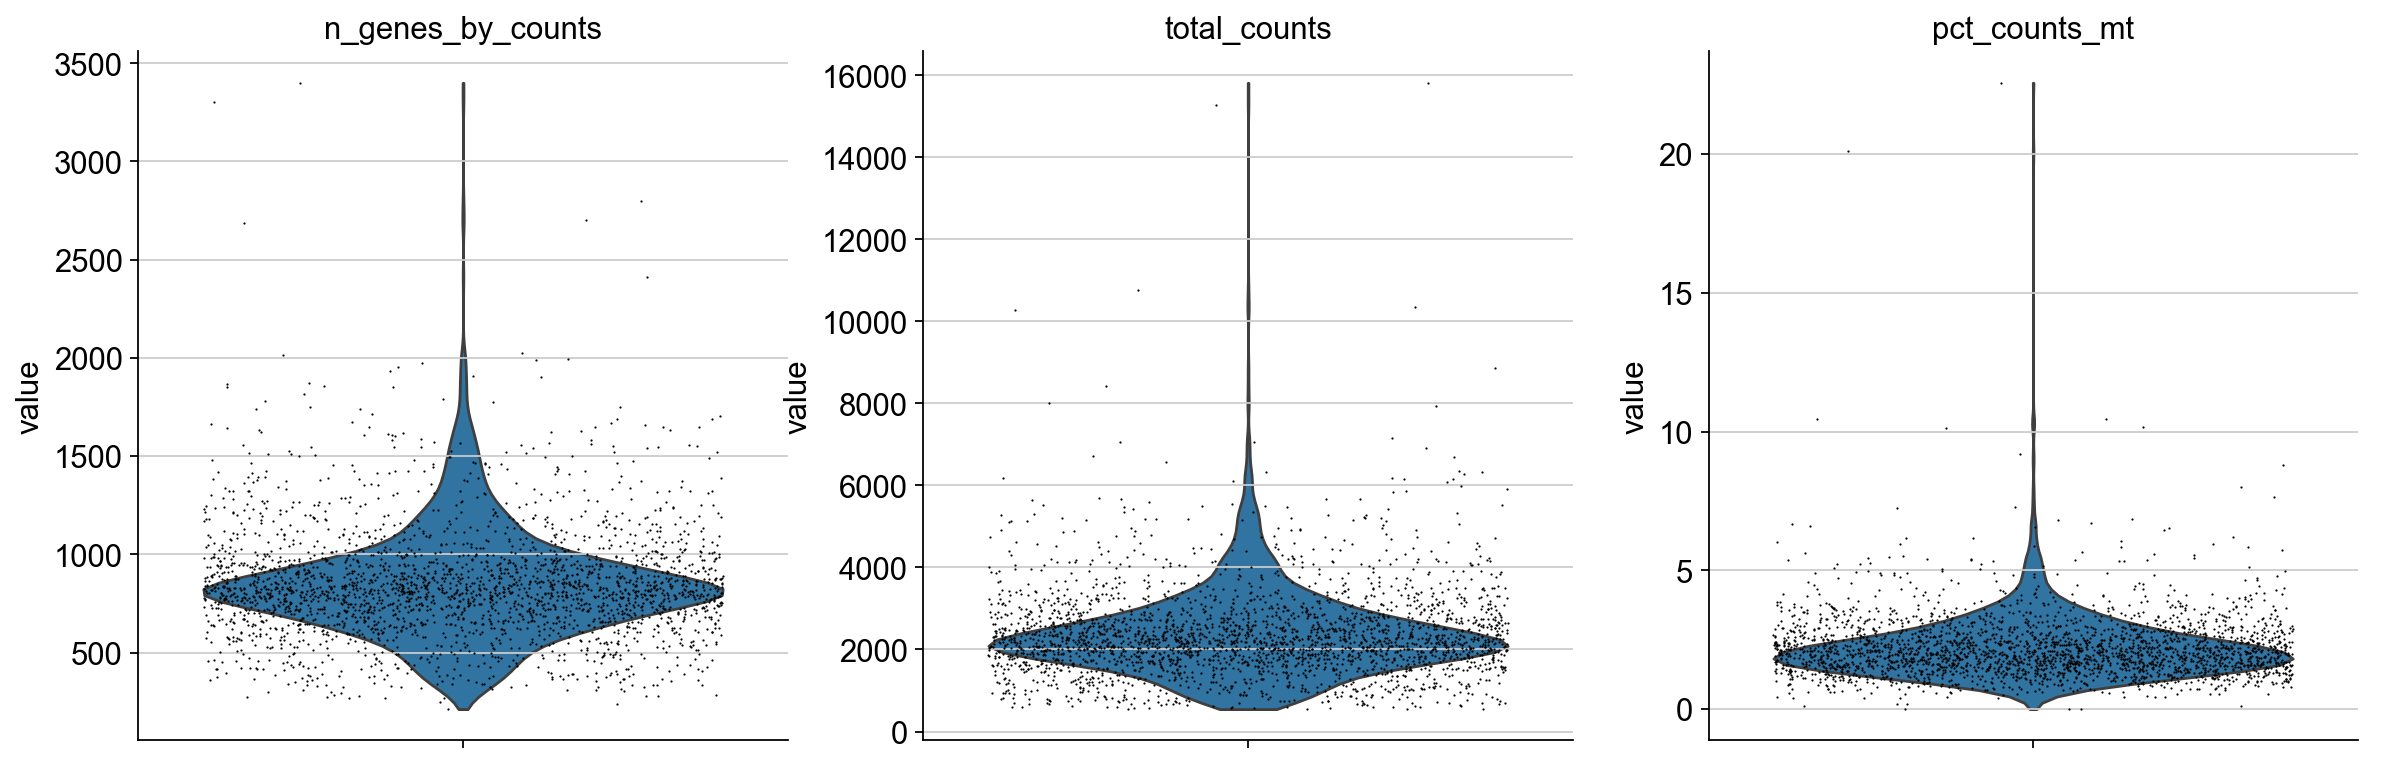

In [12]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

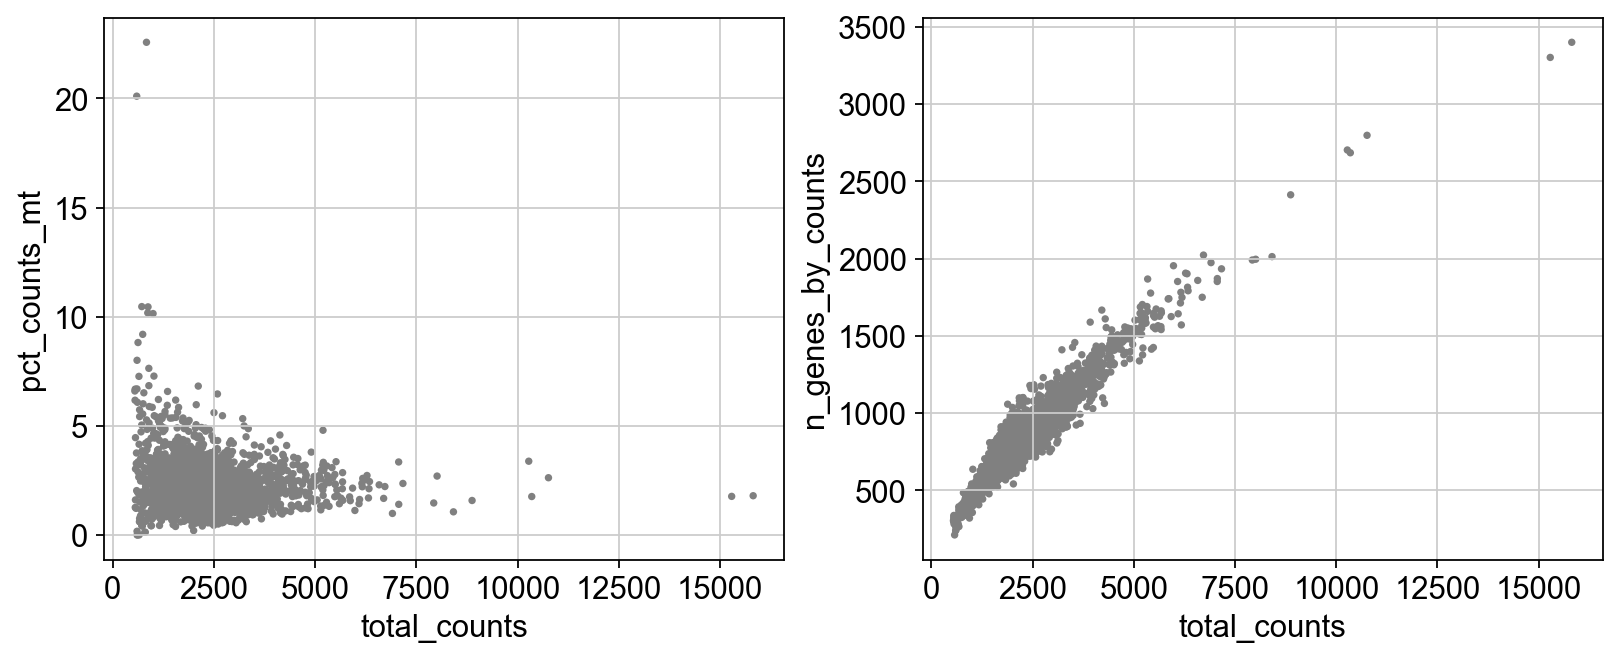

In [13]:
fig, axs = plt.subplots(1, 2, # 1行2列
                        figsize=(10, 4), # (width, height)英寸
                        layout="constrained" # 自动调整子图间距
                        )
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt", show=False, ax=axs[0])
# show=False不要立刻显示因为还有第二张图
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", show=False, ax=axs[1]);

# 注：fig, axs = plt.subplots(2, 3)的话子图位置写法举例：axs[0, 1]，fig只表示整张图

In [14]:
adata = adata[
    (adata.obs.n_genes_by_counts < 2500) & (adata.obs.n_genes_by_counts > 200) & (adata.obs.pct_counts_mt < 5),
    :,
].copy()
# AnnData切片格式：adata[细胞, 基因]，此处表示基因全保留
adata.layers["counts"] = adata.X.copy()

保留检测到的基因数少于 2500 的细胞。检测到基因过多的细胞可能包含 doublet
保留检测到的基因数大于 200 的细胞。基因数太少通常表示 RNA 含量低或细胞质量较差
保留线粒体 counts 比例低于 5% 的细胞。线粒体比例偏高可能表示细胞膜受损或细胞处于低质量状态

In [15]:
sc.pp.normalize_total(adata, target_sum=1e4) # target_sum指定放缩目标值
sc.pp.log1p(adata)

normalizing counts per cell
    finished (0:00:00)


In [16]:
%pip install scikit-misc

In [17]:
sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    n_top_genes=2000,
    flavor="seurat_v3",
)

extracting highly variable genes
--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)


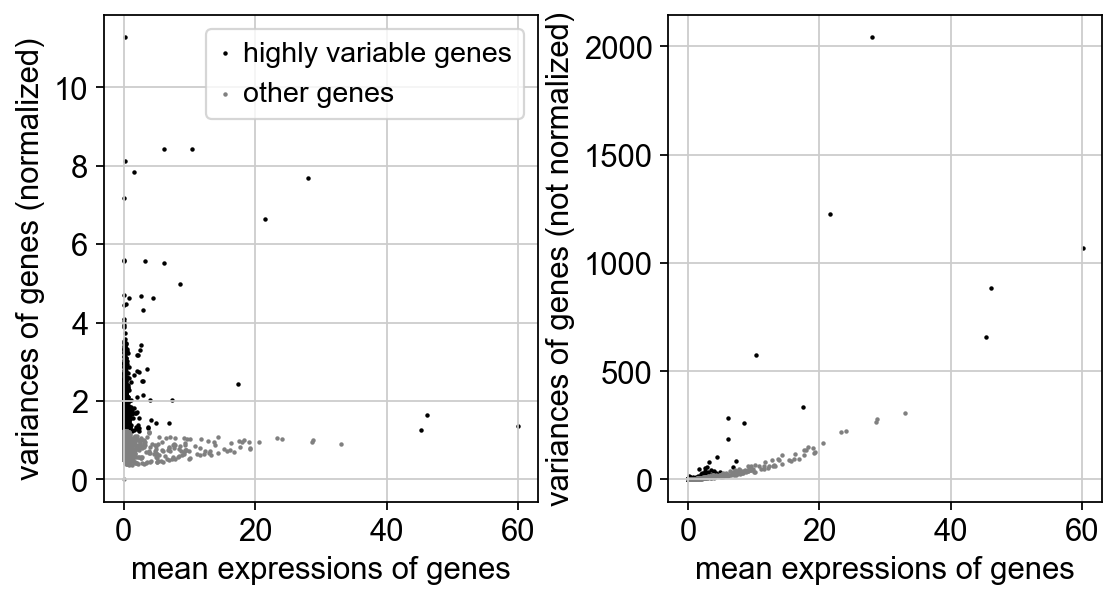

In [18]:
sc.pl.highly_variable_genes(adata)
# 纵轴是基因方差variances

In [19]:
adata.layers["scaled"] = adata.X.toarray()
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"], layer="scaled")
# 基因表达值=beta_0+beta_1*总 counts+beta_2*线粒体百分比+残差
# 将表达量残差（=实际表达值-模型预测值）替代
sc.pp.scale(adata, max_value=10, layer="scaled")
# 标准化 用z替换，z=（残差-残差均值）/残差标准差

regressing out ['total_counts', 'pct_counts_mt']
    finished (0:00:00)


这里选择了"total_counts", "pct_counts_mt"作为回归的参数，默认了细胞中的基因表达量可能与总counts和线粒体基因counts存在线性关系，认为用实际值减去回归后的模拟值更能反映基因真实显著表达的细胞区域

# Principal component analysis

In [20]:
sc.pp.pca(adata, layer="scaled", svd_solver="arpack")
# 默认使用筛选的2000个高变基因做pca
# sc.pp.pca 等价 sc.tl.pca

computing PCA
    with n_comps=50
    finished (0:00:01)


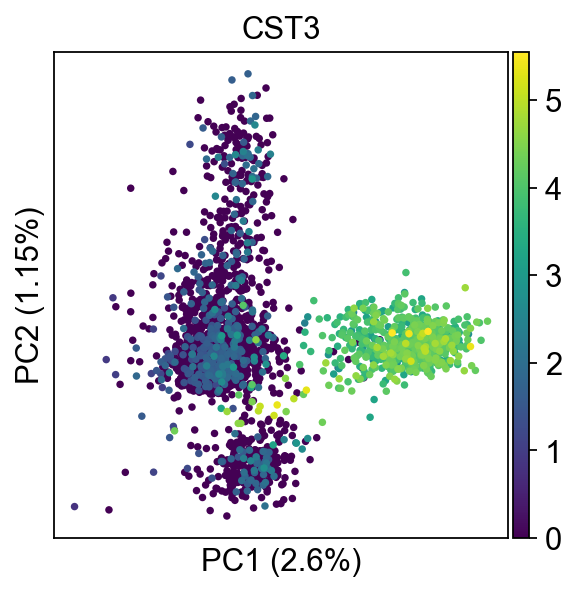

In [21]:
sc.pl.pca(adata, annotate_var_explained=True, color="CST3")
# annotate_var_explained=True在坐标轴标签中显示主成分解释的方差百分比
# 按pc1,2作图，以CST3表达量着色

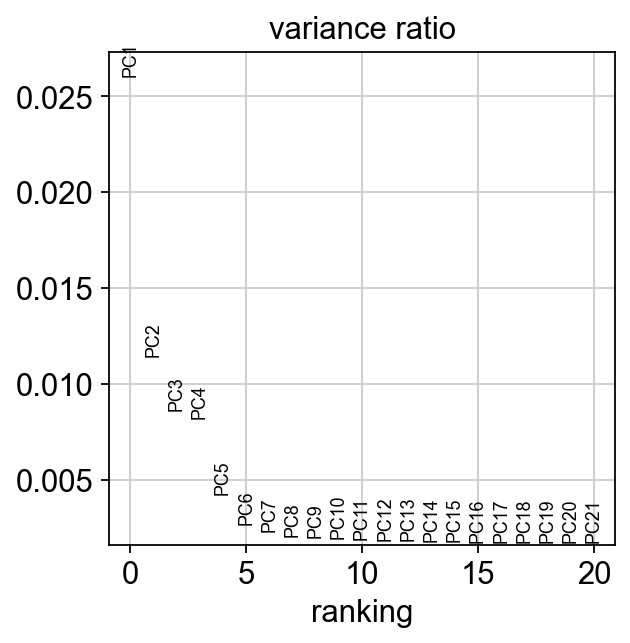

In [22]:
sc.pl.pca_variance_ratio(adata, n_pcs=20)

f:\anaconda\envs\pytorch\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8942 (\N{VERTICAL ELLIPSIS}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


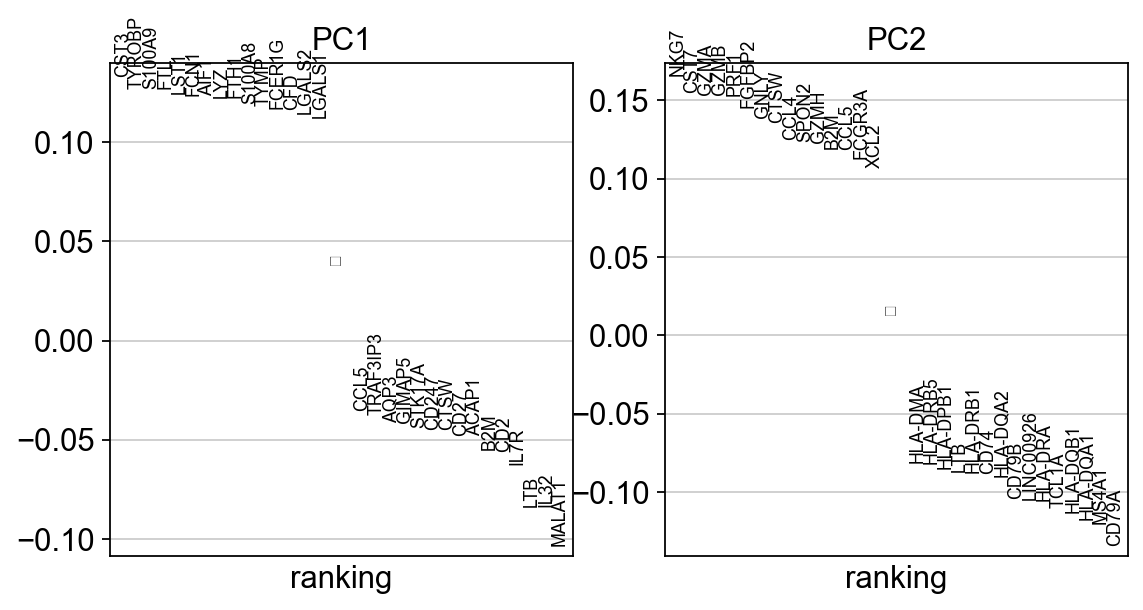

In [23]:
sc.pl.pca_loadings(adata, components=(1, 2), include_lowest=True)
# 对每一个PC = a_i*gene_i的求和，a_i为系数
# 画出pc1和pc2的基因贡献度，纵轴为a_i

# Computing the neighborhood graph

In [24]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)

computing neighbors
    using 'X_pca' with n_pcs = 40
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:08)


# Embedding the neighborhood graph

In [25]:
sc.tl.umap(adata)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


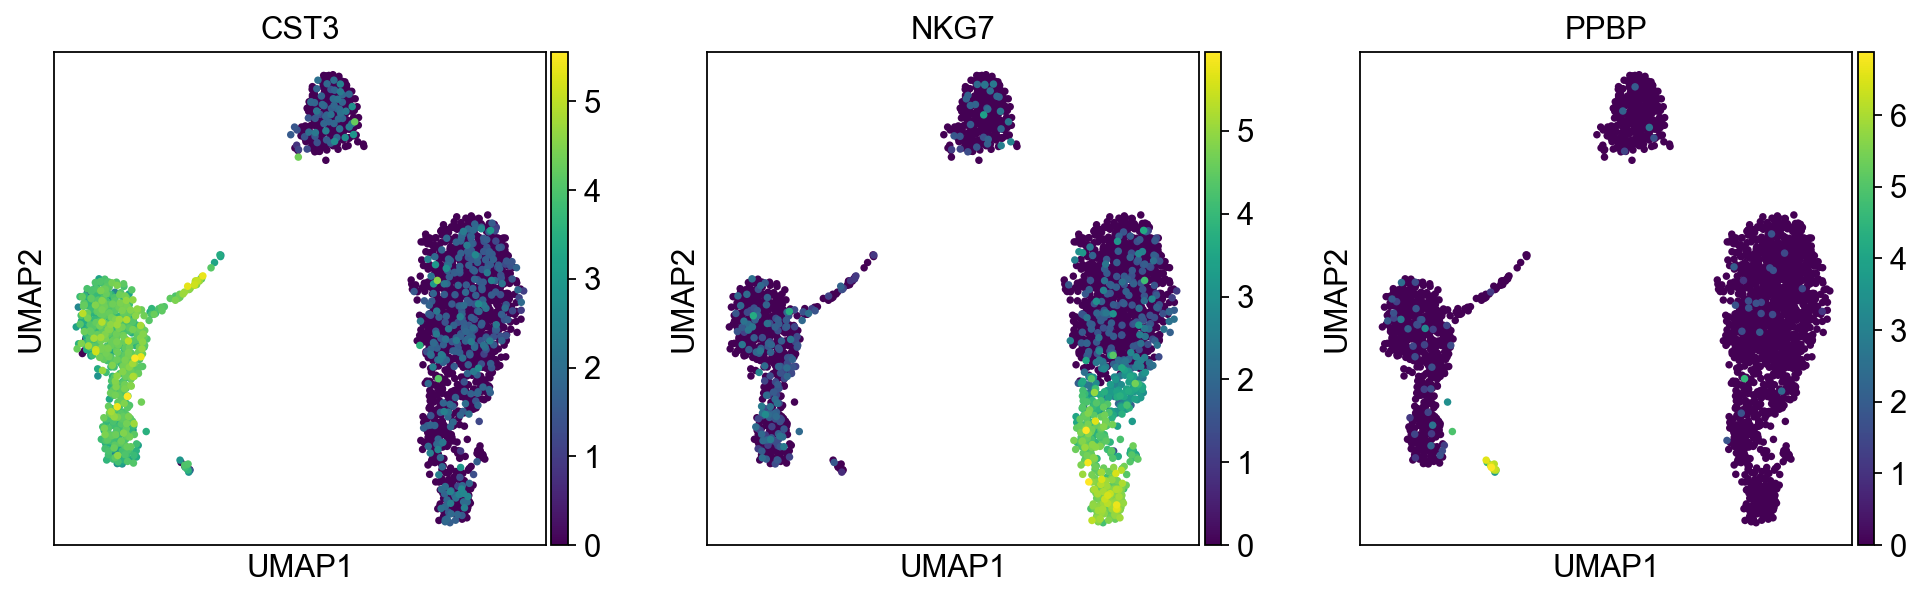

In [26]:
sc.pl.umap(adata, color=["CST3", "NKG7", "PPBP"])

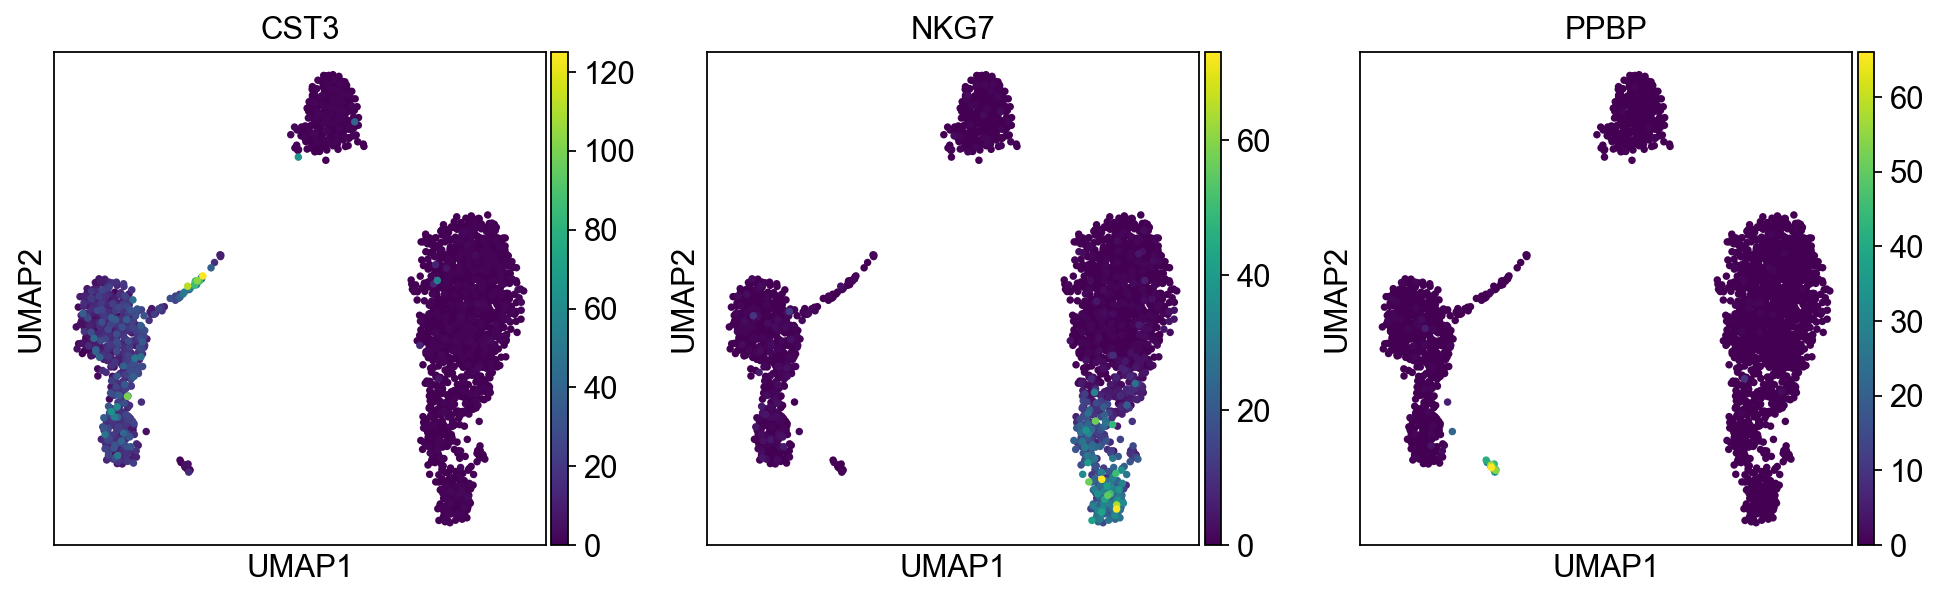

In [27]:
sc.pl.umap(adata, color=["CST3", "NKG7", "PPBP"], layer="counts")

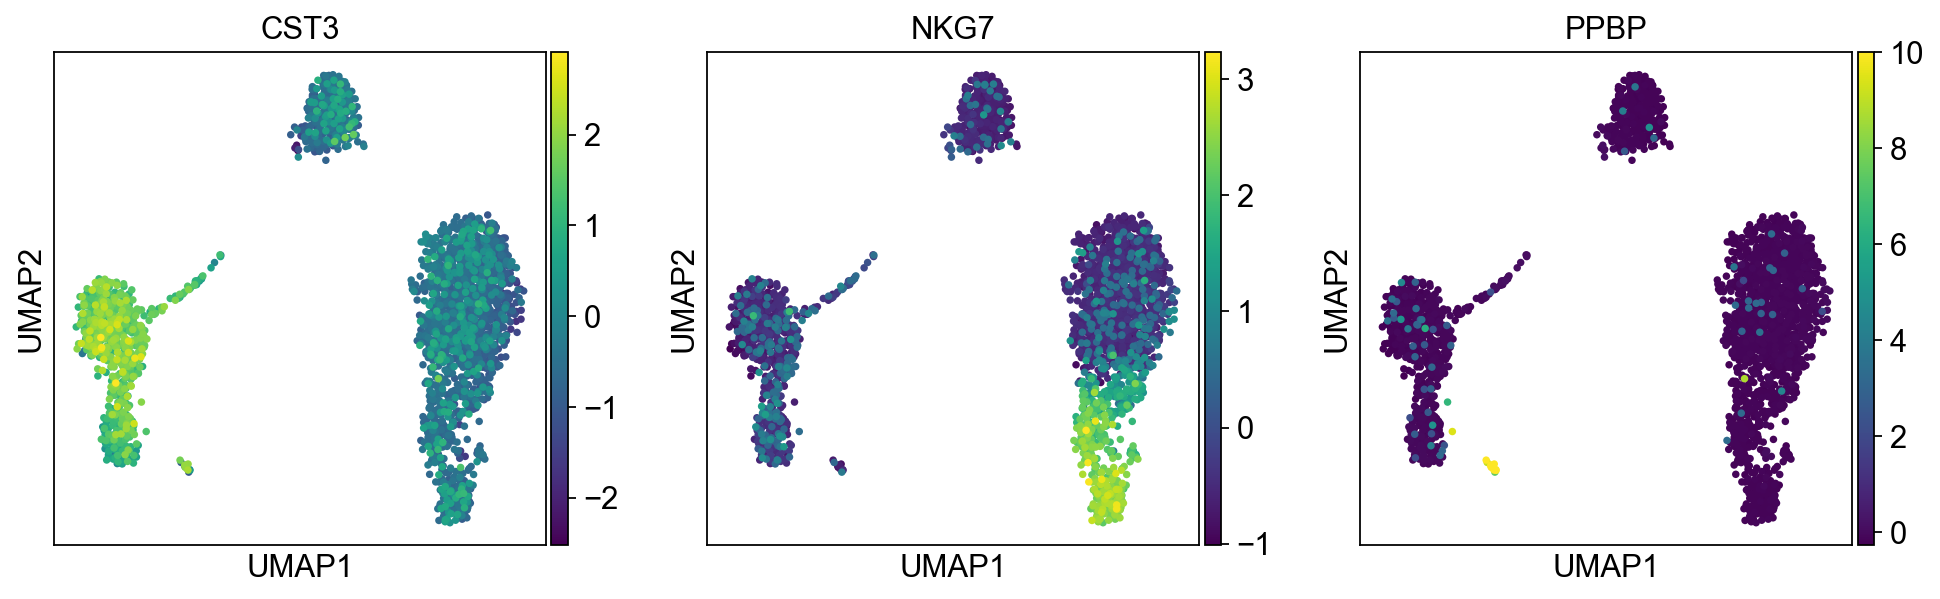

In [28]:
sc.pl.umap(adata, color=["CST3", "NKG7", "PPBP"], layer="scaled")

三幅图的差别在于使用的矩阵不同，第一张是counts的X矩阵，QC 过滤后保留的原始计数，没有归一化；第二张是总量归一化至10000再log1p后的X矩阵；第三张是scaled的X矩阵，在图二基础上还回归掉了total_counts、pct_counts_mt相关变化，再按基因标准化并截断极端值

# Clustering the neighborhood graph

In [29]:
sc.tl.leiden(
    adata,
    resolution=0.7,
    random_state=0, # 固定随机种子
    flavor="igraph",
    n_iterations=2,
    directed=False, # Scanpy先前程生成的connectivities通常是对称的
    # 将图作为无向图处理，不区分连接方向
)

running Leiden clustering
    finished: found 8 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


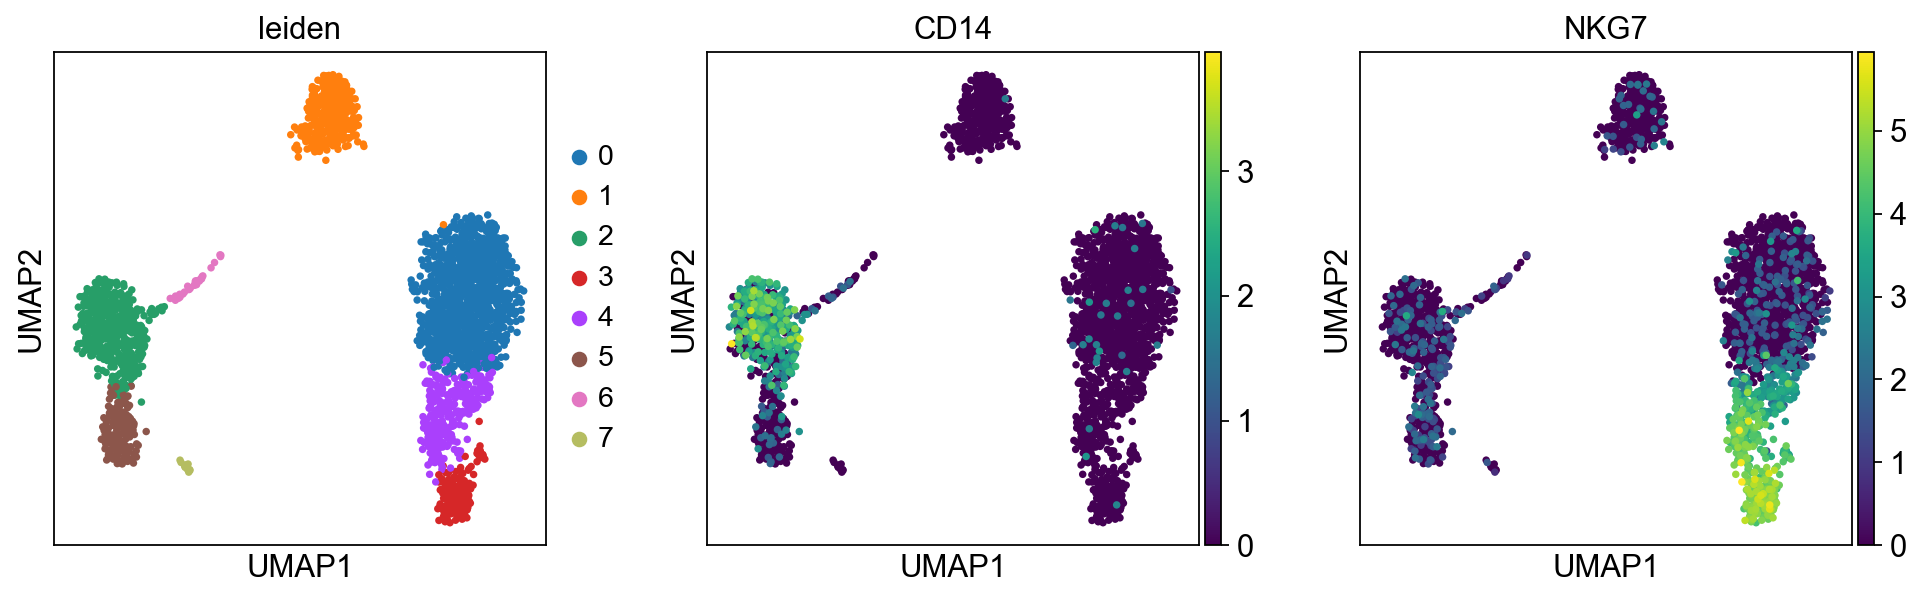

In [30]:
sc.pl.umap(adata, color=["leiden", "CD14", "NKG7"])

# Finding marker genes

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


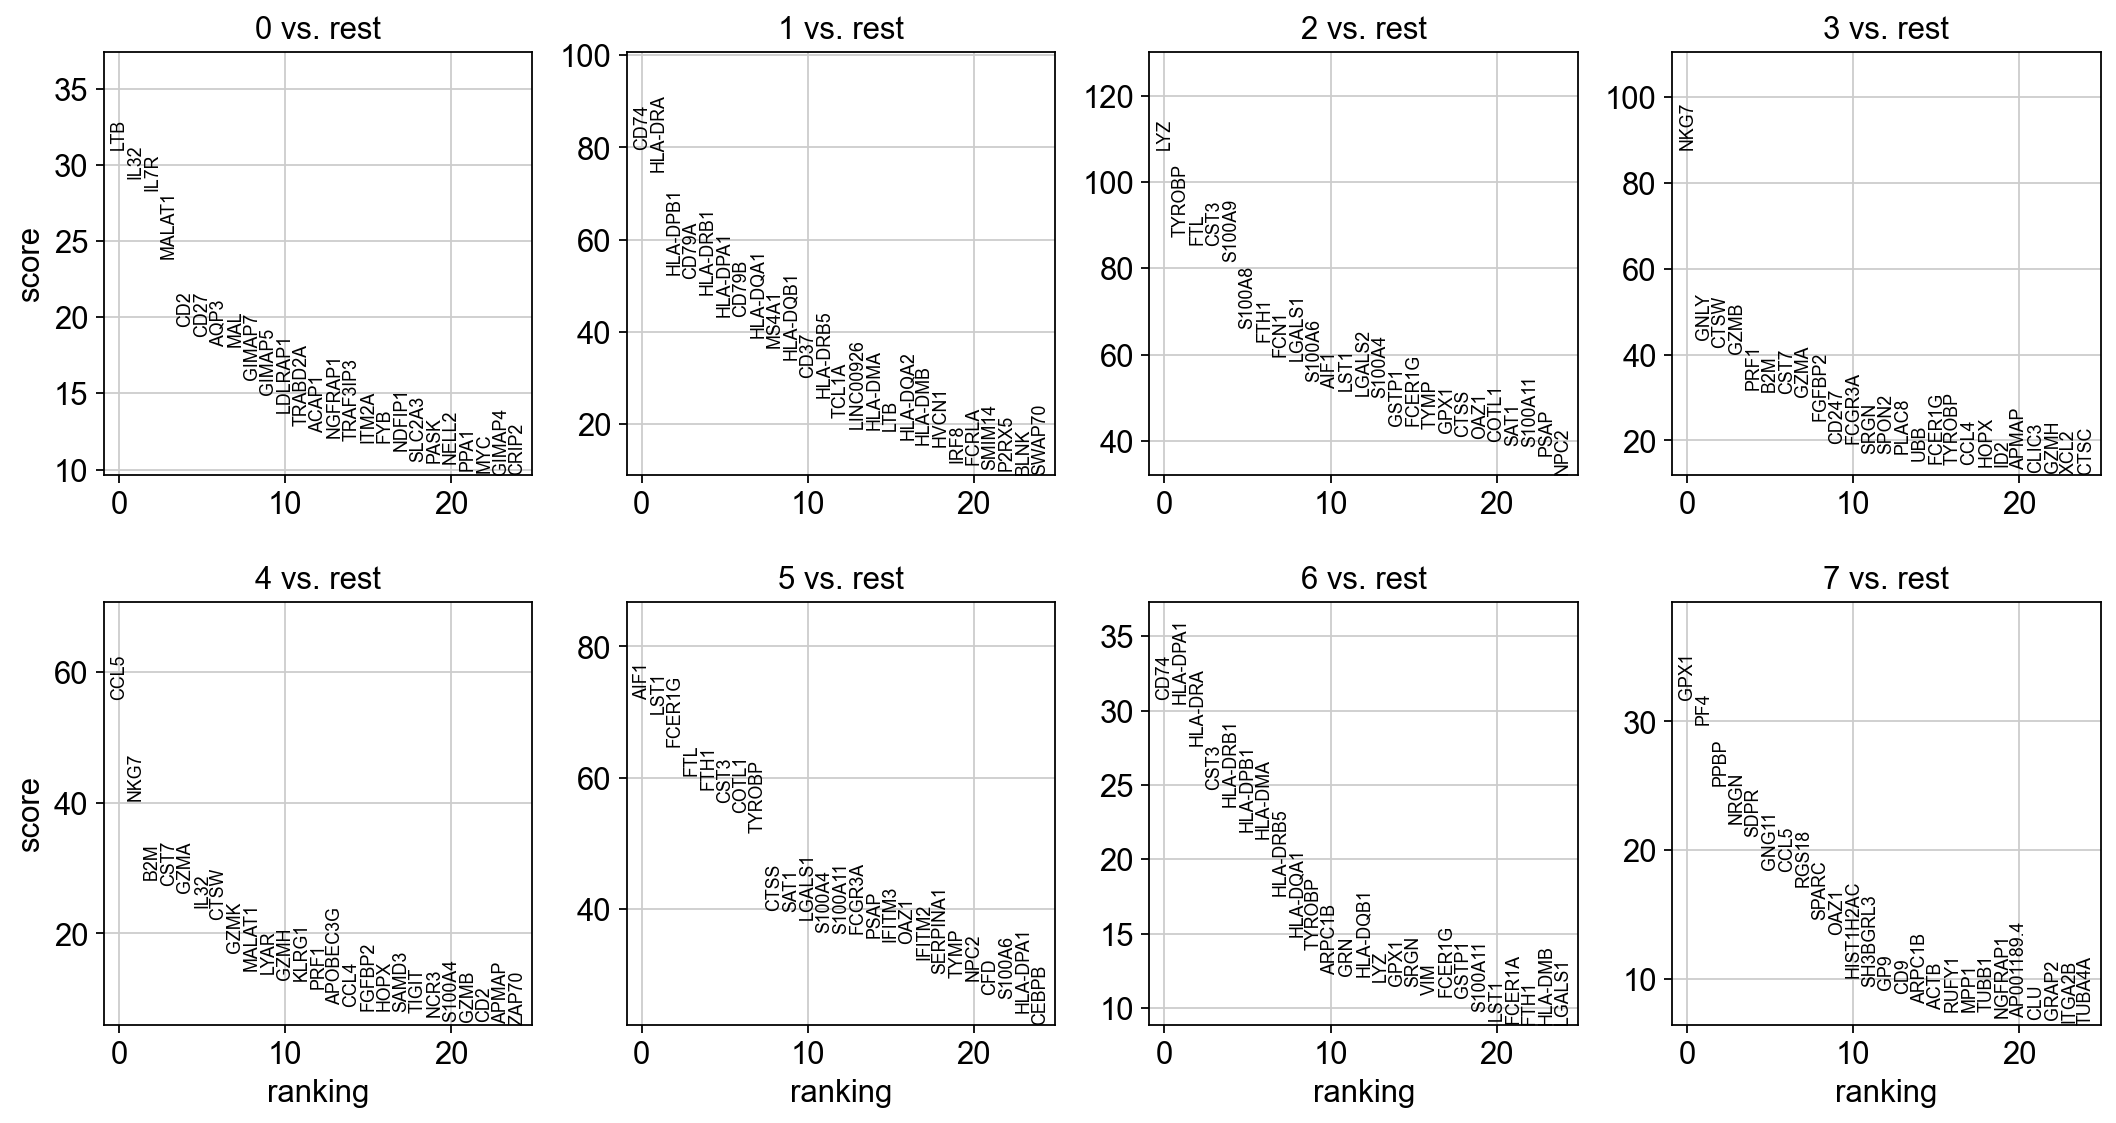

In [31]:
sc.tl.rank_genes_groups(adata, "leiden", mask_var="highly_variable", method="t-test")
# mask_var="highly_variable"限制只在先前的高变基因中筛选
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)
# sharey=Fals各面板独立设置纵轴范围，纵轴是t统计量

In [32]:
sc.settings.verbosity = 2

ranking genes
    finished (0:00:00)


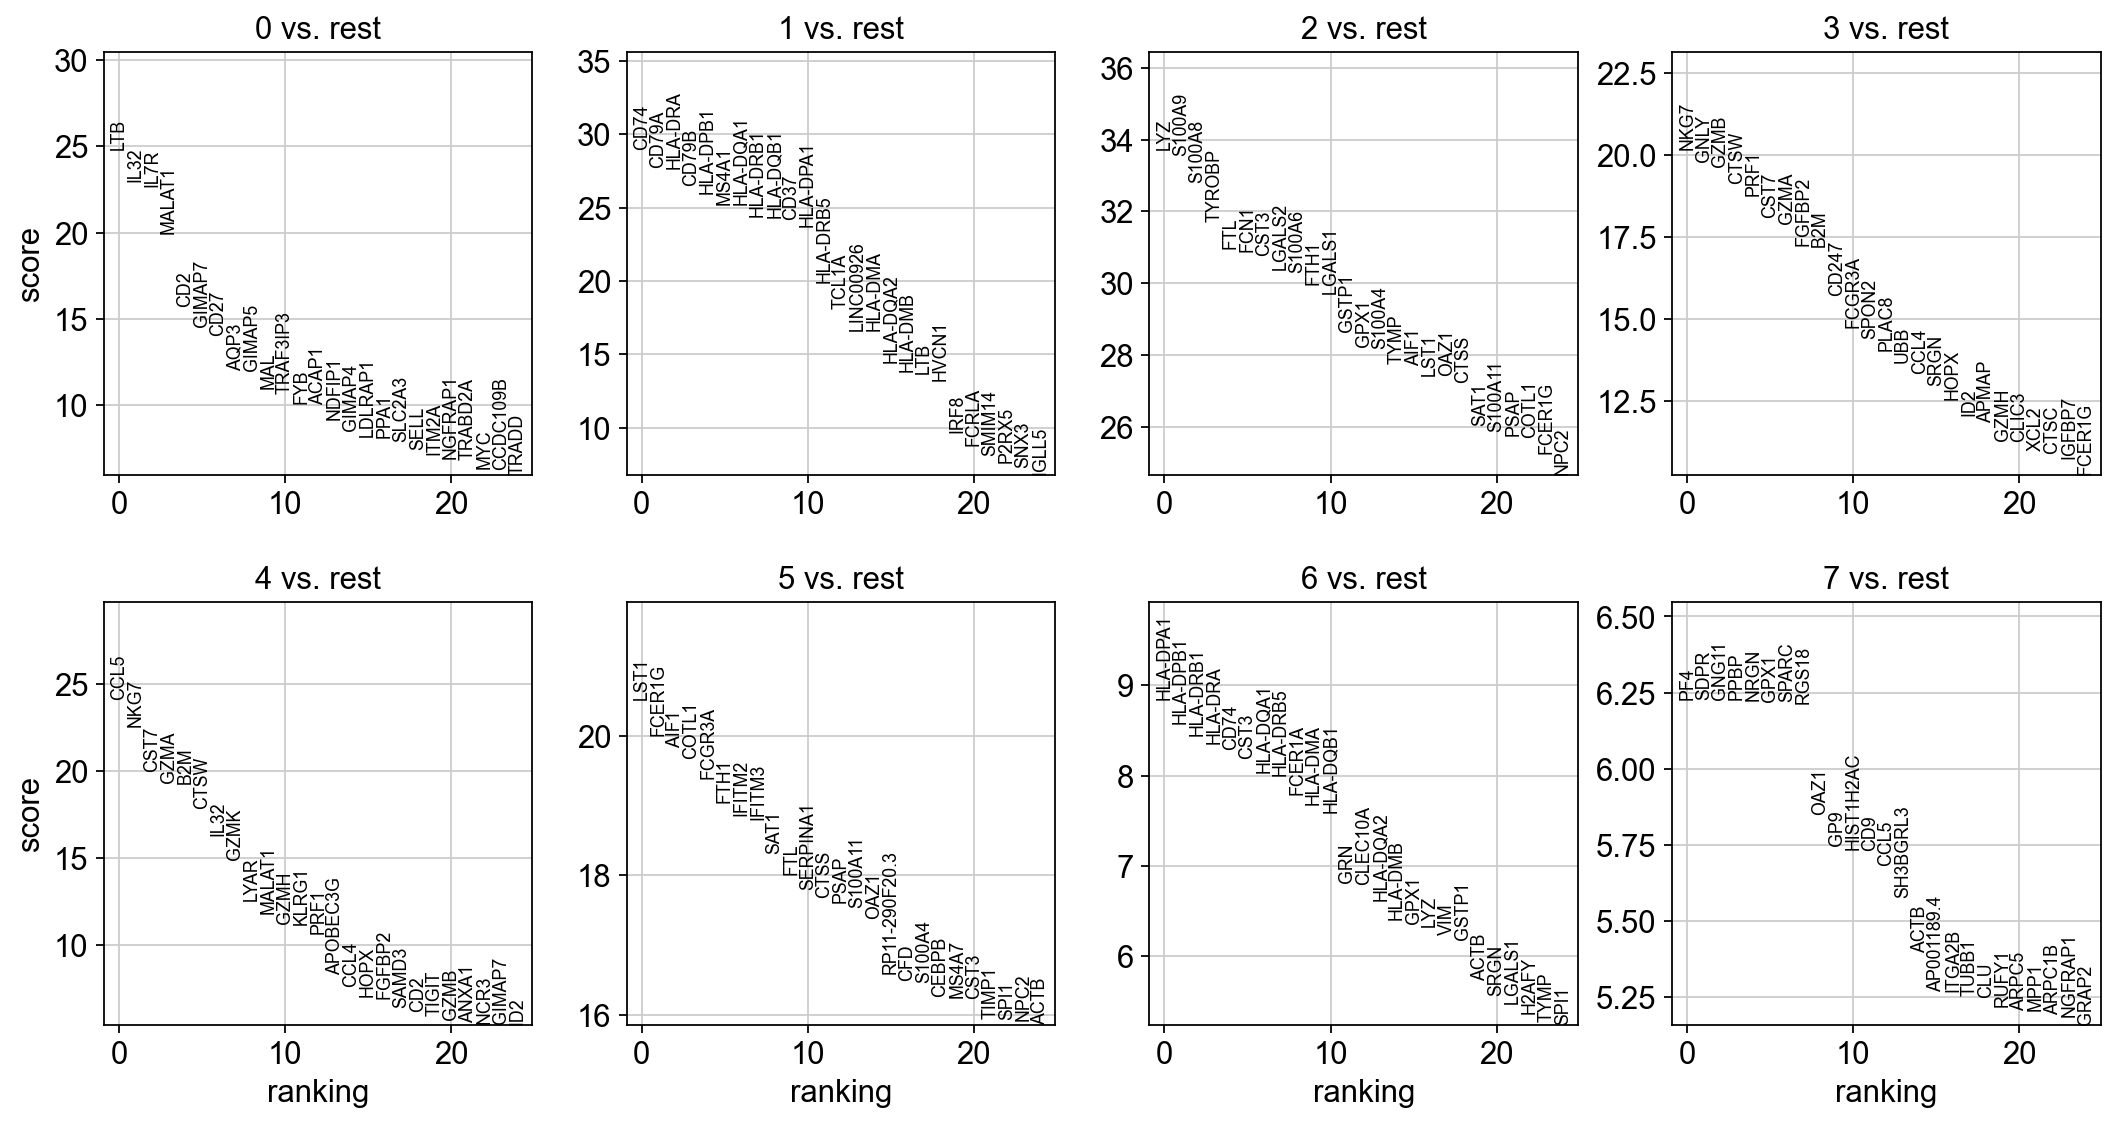

In [33]:
# 再用秩和检验做一次
sc.tl.rank_genes_groups(adata, "leiden", mask_var="highly_variable", method="wilcoxon")
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

In [34]:
# 保存以上adata分析数据
adata.write(results_file)

ranking genes
    finished (0:00:00)


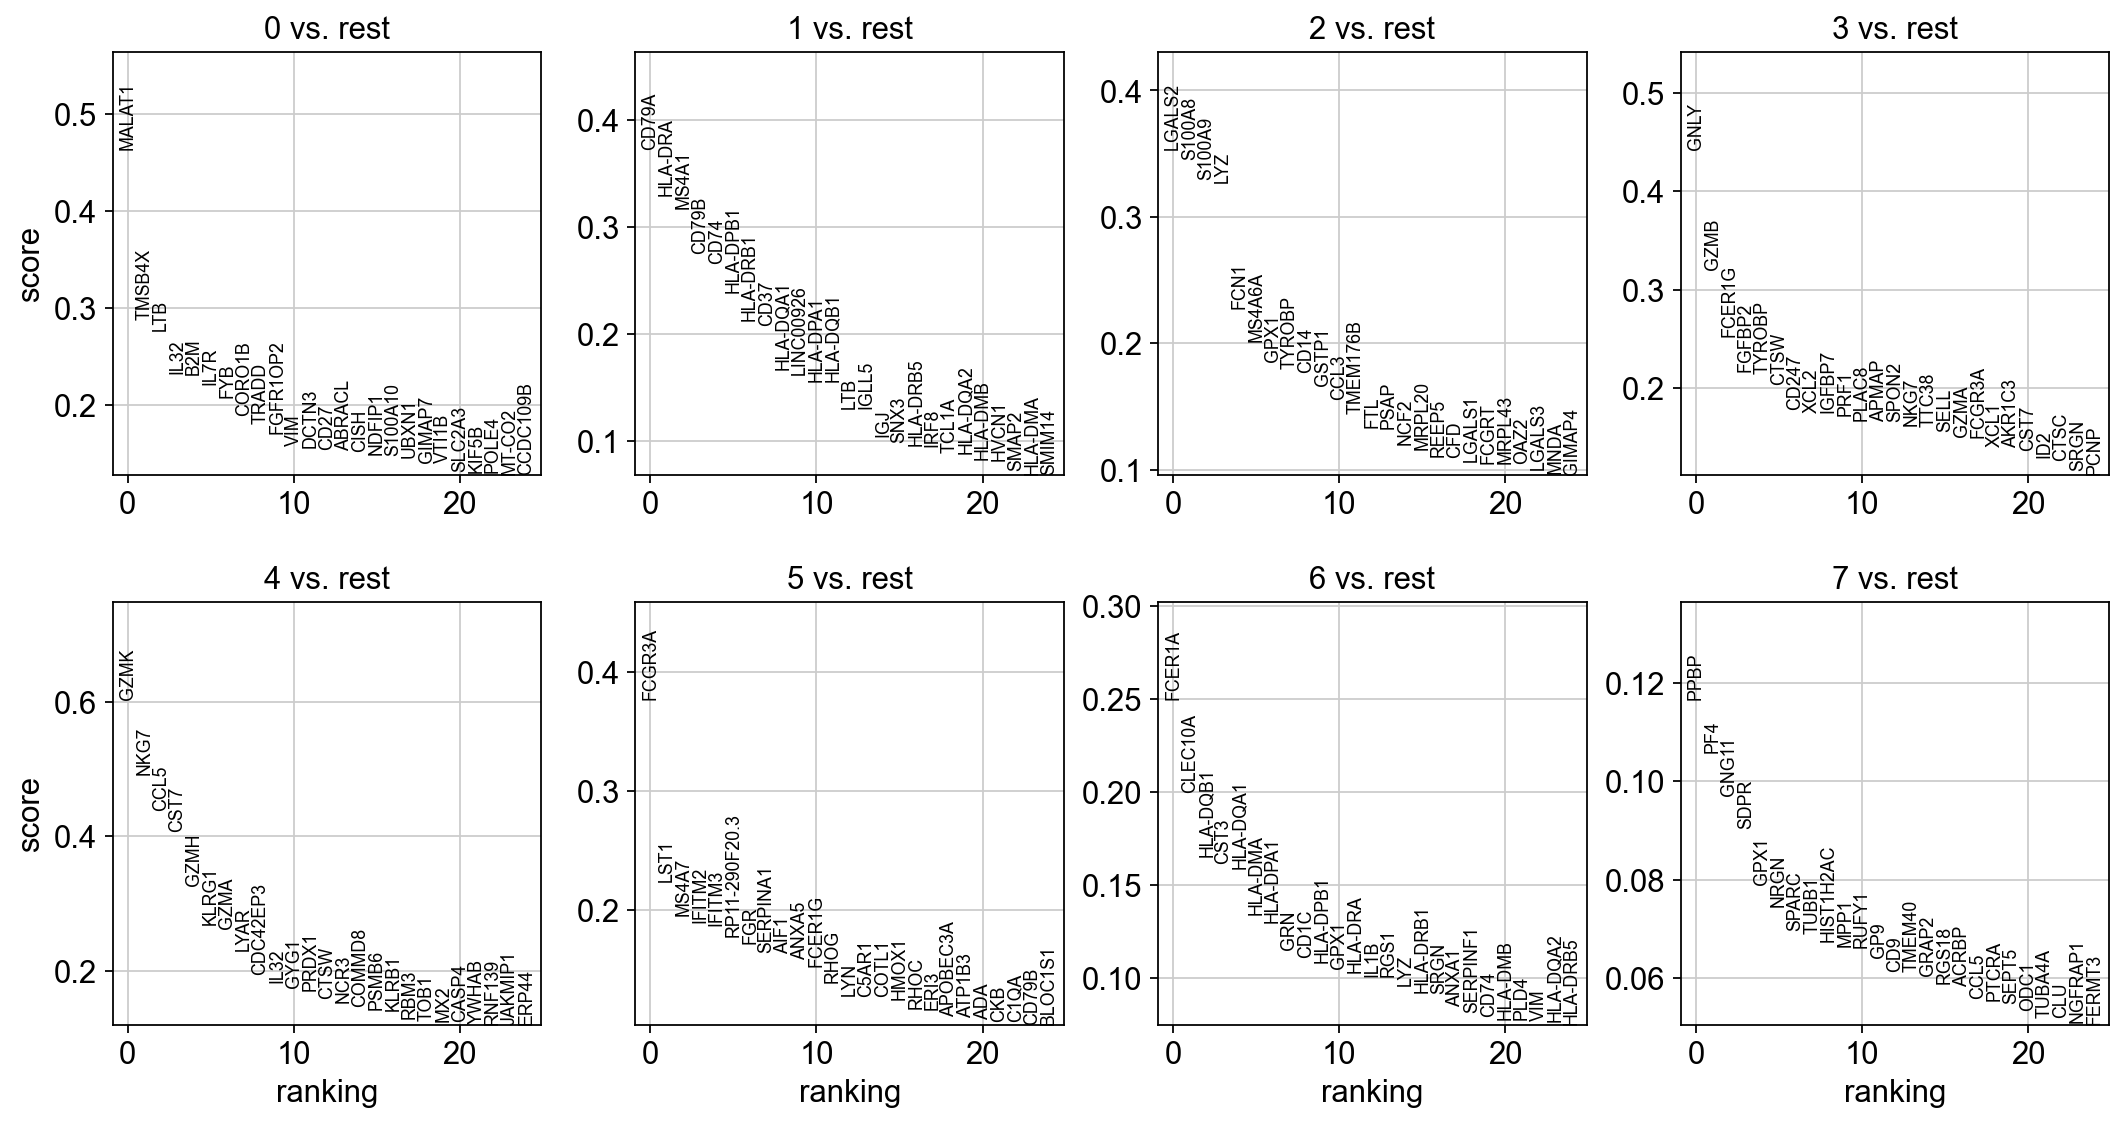

In [35]:
# 换用逻辑回归
sc.tl.rank_genes_groups(adata, "leiden", mask_var="highly_variable", method="logreg", max_iter=1000)
# max_iter=1000限制最大迭代次数1000
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

In [36]:
marker_genes = [
    *["IL7R", "CD79A", "MS4A1", "CD8A", "CD8B", "LYZ", "CD14"],
    *["LGALS3", "S100A8", "GNLY", "NKG7", "KLRB1"],
    *["FCGR3A", "MS4A7", "FCER1A", "CST3", "PPBP"],
] # 人为给定的marker基因

In [37]:
adata = sc.read(results_file) 
# 这里用的是保存前的排名，也就是秩和检验做的排名，覆盖掉了逻辑回归的结果

In [38]:
pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(5)
# uns中存储的一般是分析参数、统计结果、配色、排名等

,0,1,2,3,4,5,6,7
0,LTB,CD74,LYZ,NKG7,CCL5,LST1,HLA-DPA1,PF4
1,IL32,CD79A,S100A9,GNLY,NKG7,FCER1G,HLA-DPB1,SDPR
2,IL7R,HLA-DRA,S100A8,GZMB,CST7,AIF1,HLA-DRB1,GNG11
3,MALAT1,CD79B,TYROBP,CTSW,GZMA,COTL1,HLA-DRA,PPBP
4,CD2,HLA-DPB1,FTL,PRF1,B2M,FCGR3A,CD74,NRGN


In [ ]:
result = adata.uns["rank_genes_groups"]
groups = result["names"].dtype.names
# dtype.names取出聚类编号
pd.DataFrame({f"{group}_{key}": result[key][group] for group in groups for key in ["names", "pvals"]}).head(5)
# group是groups中的编号，字符串key是names或pvals
# f"{group}_{key}" 将聚类编号和key组合成新的列名

,0_names,0_pvals,1_names,1_pvals,2_names,2_pvals,3_names,3_pvals,4_names,4_pvals,5_names,5_pvals,6_names,6_pvals,7_names,7_pvals
0,LTB,4.924512e-136,CD74,1.972305e-184,LYZ,2.283102e-249,NKG7,1.695005e-90,CCL5,2.539217e-128,LST1,1.219211e-93,HLA-DPA1,9.083160e-19,PF4,4.722886e-10
1,IL32,9.595285e-117,CD79A,1.882747e-169,S100A9,9.953529e-247,GNLY,2.091409e-87,NKG7,1.779507e-112,FCER1G,4.872332e-89,HLA-DPB1,1.012875e-17,SDPR,4.733899e-10
2,IL7R,8.223848e-114,HLA-DRA,2.840744e-168,S100A8,7.353438e-236,GZMB,4.301595e-86,CST7,1.496015e-88,AIF1,1.527480e-87,HLA-DRB1,3.140833e-17,GNG11,4.733899e-10
3,MALAT1,9.168683e-89,CD79B,1.868216e-154,TYROBP,6.599034e-221,CTSW,1.453698e-81,GZMA,4.367645e-83,COTL1,2.926464e-86,HLA-DRA,6.528837e-17,PPBP,4.744938e-10
4,CD2,1.387825e-55,HLA-DPB1,3.333386e-148,FTL,1.173436e-210,PRF1,1.647940e-78,B2M,1.190639e-82,FCGR3A,8.680798e-84,CD74,1.090345e-16,NRGN,4.800511e-10


ranking genes
    finished (0:00:00)


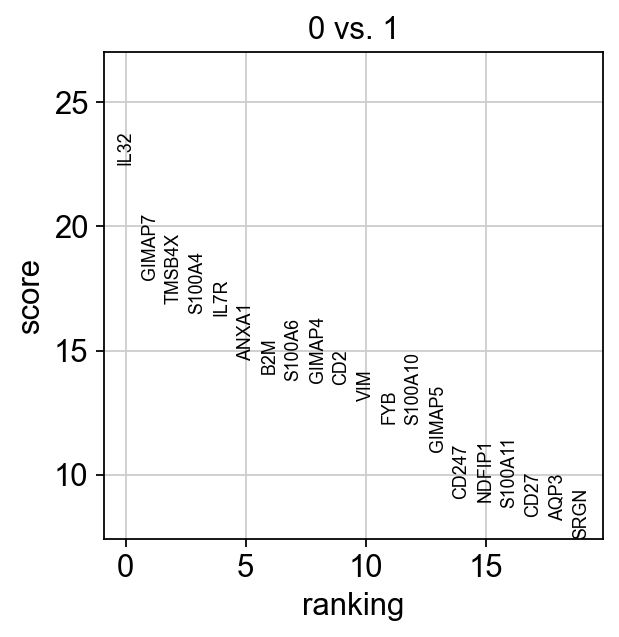

In [44]:
sc.tl.rank_genes_groups(
    adata,
    "leiden",
    mask_var="highly_variable",
    groups=["0"],
    reference="1",
    method="wilcoxon",
)
sc.pl.rank_genes_groups(adata, groups=["0"], n_genes=20)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\__init__.py:1328: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ax.set_xticklabels(new_gene_names, rotation="vertical")


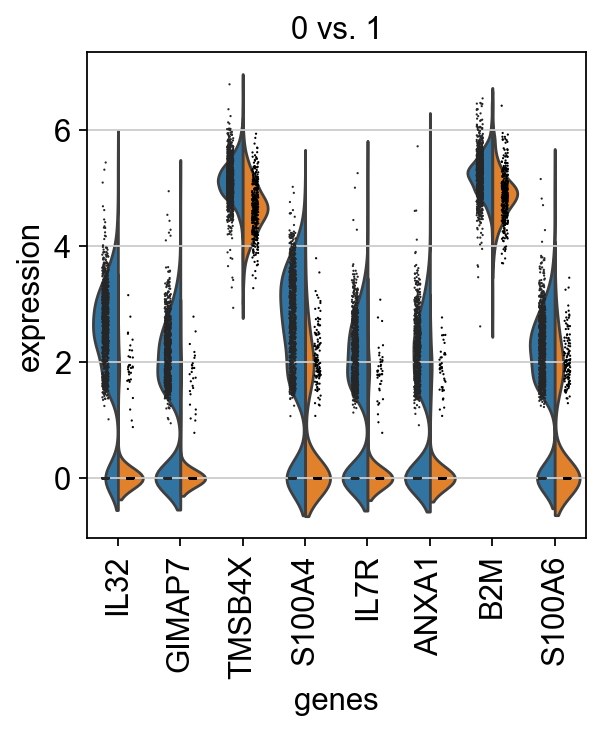

In [45]:
sc.pl.rank_genes_groups_violin(adata, groups="0", n_genes=8)

以上是专门比较 Cluster 0 和 Cluster 1，将目标群设置为0，1作为参考群，寻找能区分这两个群的基因
但是由于sc.tl.rank_genes_groups中groups=["0"],reference="1"会使得“Cluster 0 vs Cluster 1”的结果覆盖adata.uns["rank_genes_groups"]，所以之后的操作要恢复一次之前保存的结果

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\__init__.py:1328: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ax.set_xticklabels(new_gene_names, rotation="vertical")


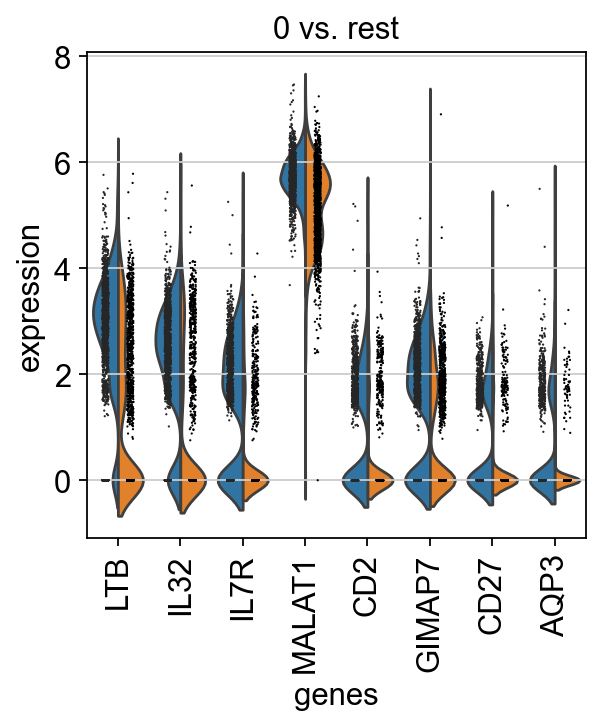

In [46]:
adata = sc.read(results_file)
sc.pl.rank_genes_groups_violin(adata, groups="0", n_genes=8)
# 相当于以0为目标群，剩下的为参考群

也可直接根据基因来比较

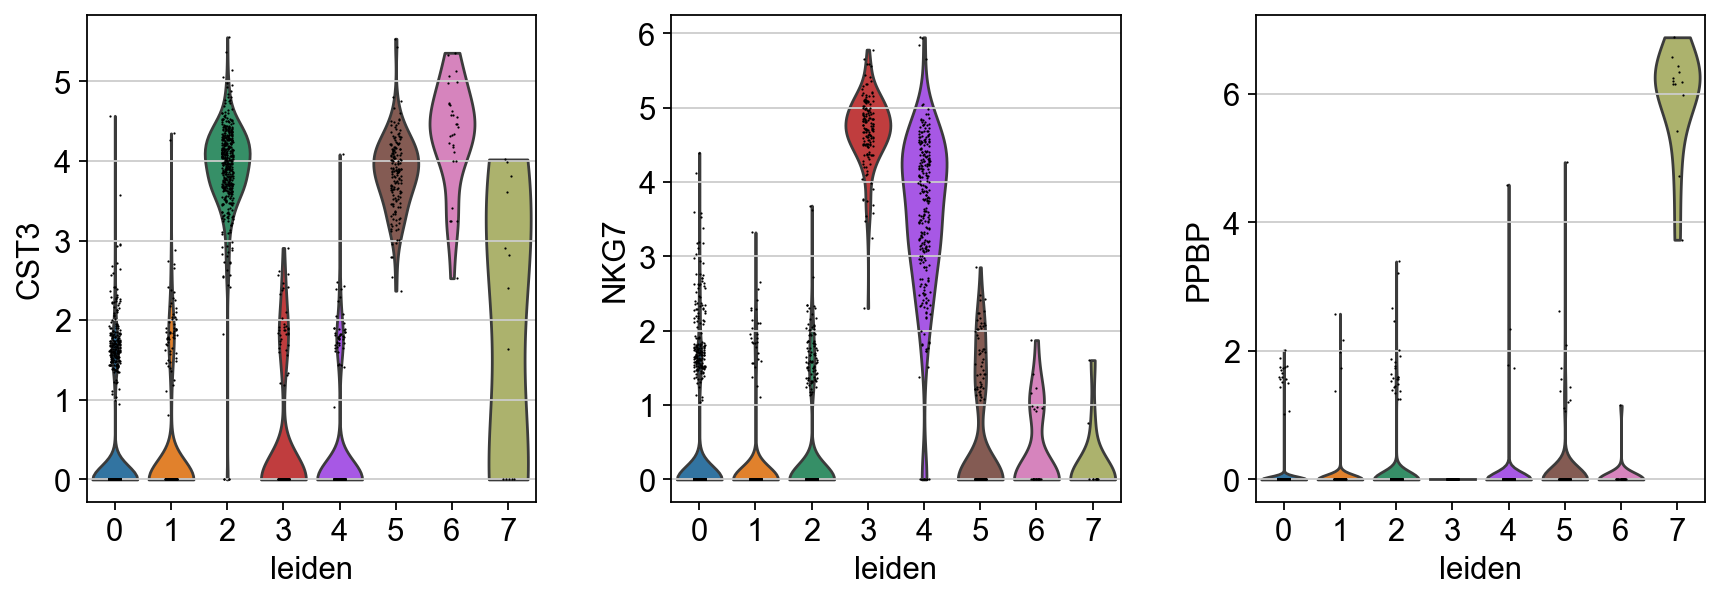

In [ ]:
sc.pl.violin(adata, ["CST3", "NKG7", "PPBP"], groupby="leiden")

将leiden聚类名字手动修改

In [48]:
new_cluster_names = [
    "CD4 T",
    "B",
    "CD14+ Monocytes",
    "NK",
    "CD8 T",
    "FCGR3A+ Monocytes",
    "Dendritic",
    "Megakaryocytes",
]
adata.rename_categories("leiden", new_cluster_names)

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1267: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


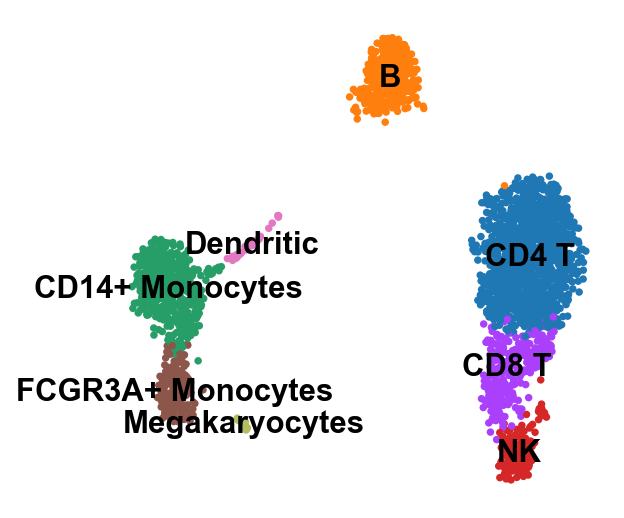

In [49]:
sc.pl.umap(adata, color="leiden", legend_loc="on data", title="", frameon=False)

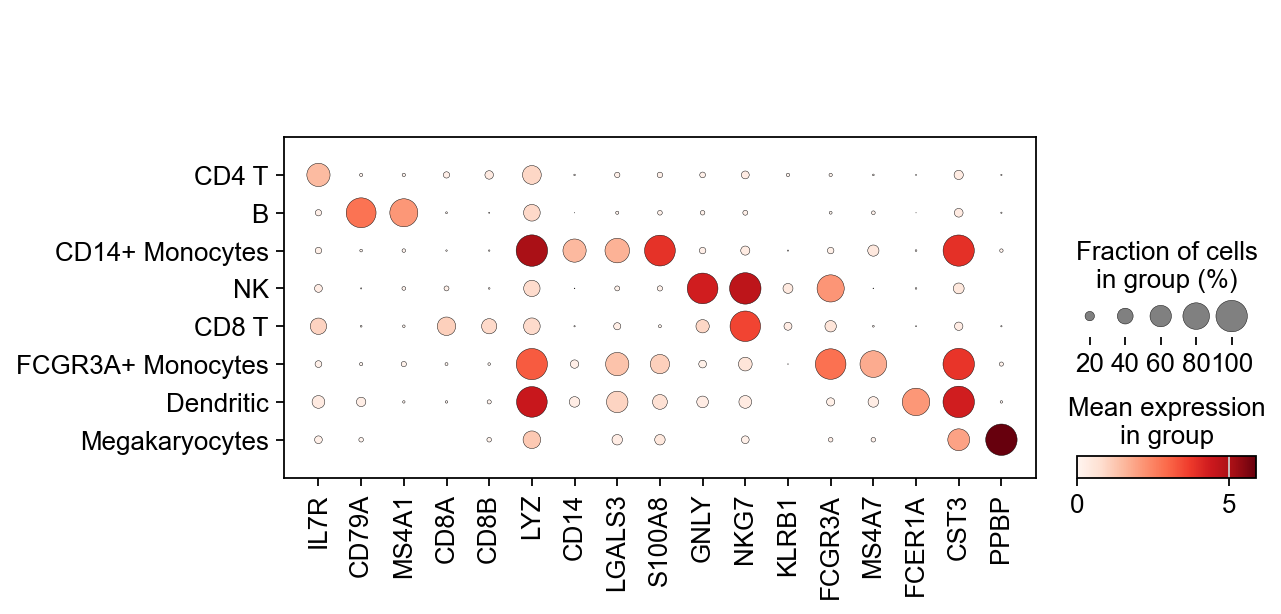

In [50]:
sc.pl.dotplot(adata, marker_genes, groupby="leiden")

f:\anaconda\envs\pytorch\lib\site-packages\scanpy\plotting\_stacked_violin.py:505: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(**stack_kwargs))


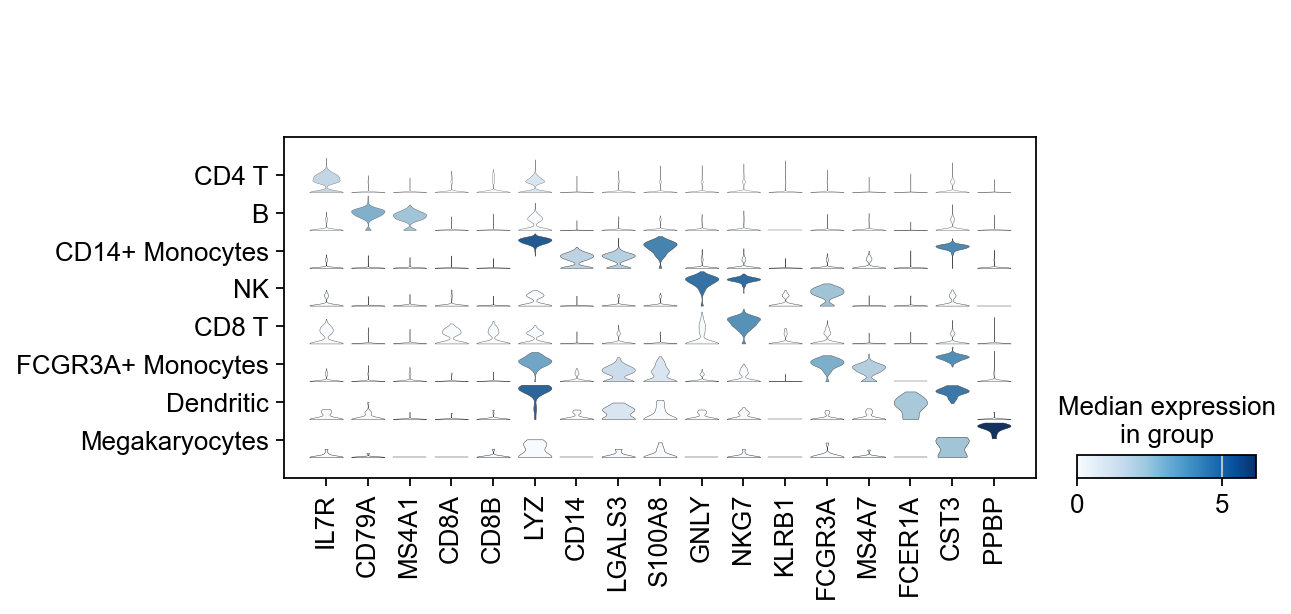

In [51]:
sc.pl.stacked_violin(adata, marker_genes, groupby="leiden")